In [87]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import ScalarFormatter
%matplotlib inline
import pandas as pd
from planet_cookbook import read_reports as rr
import os
import rebound
import seaborn as sns

sol_to_earth = 332946.078
G = 6.6743* 10**(-11) #N⋅m2/kg2
M_sun = 1.989e+33 #g
AU = 1.496e+13 #cm

In [88]:
params = {
   'axes.labelsize': 20,
   'font.size': 20,
   'legend.fontsize': 10,
   'xtick.labelsize': 20,
   'ytick.labelsize': 15,
   'text.usetex': True, #to use TeX in your labels
   'font.family':'serif',
   'axes.titlesize': 15
   }
rcParams.update(params)

In [89]:
#Color-blind friendly pallete
colors = [
    "#0C7BDC",  # Vibrant Blue
    "#E66100",  # Bright Orange
    "#40B0A6",  # Teal/Aqua
    "#8B8D8B",  # Medium Grey
    "#5D3A9B"   # Muted Purple
]

vib_blue = "#0C7BDC"
teal = "#40B0A6"
purple = "#5D3A9B" 

In [90]:
solar_system_df = pd.read_csv('../solarsystem.csv')
mercury = solar_system_df[solar_system_df['name'] == 'Mercury']
venus = solar_system_df[solar_system_df['name'] == 'Venus']
earth = solar_system_df[solar_system_df['name'] == 'Earth']
mars = solar_system_df[solar_system_df['name'] == 'Mars']

In [91]:
ueda_v5_pldf_list = rr.get_pldfs_uniform("/Users/honeyeah/Codes/data/", "ueda_v5", "ueda_v5_", 60, 299e6, 0.33)
cham_cont_pldf_list = rr.get_pldfs_uniform("/Users/honeyeah/Codes/data/", "cham_cont", "cham_cont_", 60, 299e6, 0.33)
cham_bi_tajer_pldf_list = rr.get_pldfs_uniform("/Users/honeyeah/Codes/data/", "cham_bi_tajer", "cham_simarchive_", 130, 299e6, 0.33)

/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:103: RuntimeWarning: Binary file was saved with a different version of REBOUND. Binary format might have changed. Binary file was saved with REBOUND Version 4.4.7. You are currently using REBOUND Version 4.4.8.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: RuntimeWarning: Binary file was saved with a different version of REBOUND. Binary format might have changed.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: RuntimeWarning: You have to reset function pointers after creating a reb_simulation struct with a binary file.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:103: Run

In [92]:
ueda_v5_pldf = pd.concat(ueda_v5_pldf_list)
cham_bi_tajer_pldf = pd.concat(cham_bi_tajer_pldf_list)
cham_cont_pldf = pd.concat(cham_cont_pldf_list)

In [93]:
def mercury_sim_index(masses, cmfs):
    cmf_merc =  mercury['CMF'].values[0]
    mass_merc =  mercury['m'].values[0]
    cmf_diff = np.sum((cmfs - cmf_merc)**2) / (np.average(cmfs) * len(cmfs))
    masses_diff = np.sum((masses - mass_merc)**2) / (np.average(masses) * len(masses))

    index = np.sqrt((cmf_diff + masses_diff))
    return index

def mercury_sim_index_cmf_only(cmfs):
    cmf_merc =  mercury['CMF'].values[0]
    cmf_diff = np.sum((cmfs - cmf_merc)**2) / (np.average(cmfs) * len(cmfs))

    index = np.sqrt(cmf_diff)
    return index

In [94]:
#Mercury deviation conditions
#semi_lower_bound = mercury['a'].values[0] - 0.1
#semi_upper_bound = mercury['a'].values[0] + 0.1

semi_lower_bound = 0
semi_upper_bound = 0.5

ueda_v5_mercs = ueda_v5_pldf[(ueda_v5_pldf['semi'] > semi_lower_bound) & (ueda_v5_pldf['semi'] < semi_upper_bound)]
cham_bi_tajer_mercs = cham_bi_tajer_pldf[(cham_bi_tajer_pldf['semi'] > semi_lower_bound) & (cham_bi_tajer_pldf['semi'] < semi_upper_bound)]
cham_cont_mercs = cham_cont_pldf[(cham_cont_pldf['semi'] > semi_lower_bound) & (cham_cont_pldf['semi'] < semi_upper_bound)]

In [95]:
ueda_inds = mercury_sim_index(ueda_v5_mercs['mass'].values * sol_to_earth, ueda_v5_mercs['cmf'].values)
ueda_inds_cmf = mercury_sim_index_cmf_only(ueda_v5_mercs['cmf'].values)
print("ueda_v5")
print("Merc deviation index, uniform = ", ueda_inds)
#print("Merc deviation index, CMF only = ", ueda_inds_cmf)

ueda_v5
Merc deviation index, uniform =  1.000250901655747


In [96]:
cham_bi_tajer_inds = mercury_sim_index(cham_bi_tajer_mercs['mass'].values * sol_to_earth, cham_bi_tajer_mercs['cmf'].values)
cham_bi_tajer_inds_cmf = mercury_sim_index_cmf_only(cham_bi_tajer_mercs['cmf'].values)
print("cham_bi_tajer")
print("Merc deviation index, uniform = ", cham_bi_tajer_inds)
#print("Merc deviation index, CMF only = ", cham_bi_tajer_inds_cmf)

cham_bi_tajer
Merc deviation index, uniform =  0.8976668030521654


In [97]:
cham_cont_inds = mercury_sim_index(cham_cont_mercs['mass'].values * sol_to_earth, cham_cont_mercs['cmf'].values)
cham_cont_inds_cmf = mercury_sim_index_cmf_only(cham_cont_mercs['cmf'].values)
print("cham_cont")
print("Merc deviation index, uniform = ", cham_cont_inds)
#print("Merc deviation index, CMF only = ", cham_cont_inds_cmf)

cham_cont
Merc deviation index, uniform =  0.8888229094179889


# Step funcs

In [98]:
ueda_steps = pd.read_csv("../ueda_v5/ueda_v5_grid_fulldf.csv")
cham_bi_tajer_steps = pd.read_csv("../cham_bi_tajer/cham_bi_tajer_grid_fulldf.csv")
cham_cont_steps = pd.read_csv("../cham_cont/cham_cont_grid_fulldf.csv")

ueda_steps_mercs = ueda_steps[(ueda_steps['semi'] > semi_lower_bound) & (ueda_steps['semi'] < semi_upper_bound)]
cham_bi_tajer_steps_mercs = cham_bi_tajer_steps[(cham_bi_tajer_steps['semi'] > semi_lower_bound) & (cham_bi_tajer_steps['semi'] < semi_upper_bound)]
cham_cont_steps_mercs = cham_cont_steps[(cham_cont_steps['semi'] > semi_lower_bound) & (cham_cont_steps['semi'] < semi_upper_bound)]

In [99]:
ueda_inds_step = mercury_sim_index(ueda_steps_mercs['mass'].values * sol_to_earth, ueda_steps_mercs['cmf'].values)
ueda_inds_cmf_step = mercury_sim_index_cmf_only(ueda_steps_mercs['cmf'].values)
print("ueda_v5")
print("Merc Dev index, step = ", ueda_inds_step)
print("Merc dev CMF only index, step = ", ueda_inds_cmf_step)
#print("Merc deviation index, CMF only = ", ueda_inds_cmf_step)

ueda_v5
Merc Dev index, step =  0.9841724646138078
Merc dev CMF only index, step =  0.6997645893558696


In [100]:
cham_bi_tajer_inds_step = mercury_sim_index(cham_bi_tajer_steps_mercs['mass'].values * sol_to_earth, cham_bi_tajer_steps_mercs['cmf'].values)
cham_bi_tajer_inds_cmf_step = mercury_sim_index_cmf_only(cham_bi_tajer_steps_mercs['cmf'].values)
print("cham_bi_tajer")
print("Merc deviation index, step = ", cham_bi_tajer_inds_step)
print("Merc dev CMF only index, step = ", cham_bi_tajer_inds_cmf_step)
#print("Merc deviation index, CMF only = ", cham_bi_tajer_inds_cmf_step)

cham_bi_tajer
Merc deviation index, step =  0.7813615032632969
Merc dev CMF only index, step =  0.5234262120201684


In [101]:
print("Ratio of simulated Mercury/Real Mercury mass, cham_cont = ",
      (np.average(cham_cont_steps_mercs['mass'] * sol_to_earth))/mercury['m'].values[0])

Ratio of simulated Mercury/Real Mercury mass, cham_cont =  4.068391885409278


In [102]:
print("Ratio of simulated Mercury/Real Mercury mass, cham_bi_tajer = ",
      (np.average(cham_bi_tajer_steps_mercs['mass'] * sol_to_earth))/mercury['m'].values[0])

Ratio of simulated Mercury/Real Mercury mass, cham_bi_tajer =  7.2509225388920795


In [103]:
print("Ratio of simulated Mercury/Real Mercury mass, ueda_v5 = ",
      (np.average(ueda_steps_mercs['mass'] * sol_to_earth))/mercury['m'].values[0])

Ratio of simulated Mercury/Real Mercury mass, ueda_v5 =  9.409480557025105


In [104]:
cham_cont_inds_step = mercury_sim_index(cham_cont_steps_mercs['mass'].values * sol_to_earth, cham_cont_steps_mercs['cmf'].values)
cham_cont_inds_cmf_step = mercury_sim_index_cmf_only(cham_cont_steps_mercs['cmf'].values)
print("cham_cont")
print("Merc deviation index, step = ", cham_cont_inds_step)
#print("Merc deviation index, CMF only = ", cham_cont_inds_cmf_step)

cham_cont
Merc deviation index, step =  0.6989102058502376


In [105]:
min_uniforms = np.min([cham_cont_inds, cham_bi_tajer_inds, ueda_inds])
min_step = np.min([cham_bi_tajer_inds_step, cham_cont_inds_step, ueda_inds_step])
average_all = np.average([cham_cont_inds, cham_bi_tajer_inds, ueda_inds, cham_bi_tajer_inds_step, cham_cont_inds_step, ueda_inds_step])

print("min_uniforms = ", min_uniforms)
print("min_steps = ", min_step)

min_all = np.min([min_uniforms, min_step])
print("min_all = ", min_all)

print("average_all = ", average_all)

min_uniforms =  0.8888229094179889
min_steps =  0.6989102058502376
min_all =  0.6989102058502376
average_all =  0.8751974646422073


In [106]:
uniforms_ave = {
    "Cham2013 bimod": cham_bi_tajer_inds - average_all,
    "Cham2013 cont": cham_cont_inds - average_all,
    "Ueda2021": ueda_inds - average_all
}

steps_ave = {
    "Cham2013 bimod": cham_bi_tajer_inds_step - average_all,
    "Cham2013 cont": cham_cont_inds_step - average_all,
    "Ueda2021": ueda_inds_step - average_all
}

uniforms = {
    "Cham2013 bimod": cham_bi_tajer_inds - min_all,
    "Cham2013 cont": cham_cont_inds - min_all,
    "Ueda2021": ueda_inds - min_all
}

steps = {
    "Cham2013 bimod": cham_bi_tajer_inds_step - min_all,
    "Cham2013 cont": cham_cont_inds_step - min_all,
    "Ueda2021": ueda_inds_step - min_all
}

print("Uniform : Cham2013 bimodal = ", cham_bi_tajer_inds - min_all)
print("Uniform : Cham2013 cont = ", cham_cont_inds - min_all)
print("Uniform : Ueda = ", ueda_inds - min_all)



print("Step function : Cham2013 bimodal = ", cham_bi_tajer_inds_step - min_all)
print("Step function : Cham2013 cont = ", cham_cont_inds_step - min_all)
print("Step function : Ueda = ", ueda_inds_step - min_all)

Uniform : Cham2013 bimodal =  0.19875659720192784
Uniform : Cham2013 cont =  0.18991270356775136
Uniform : Ueda =  0.3013406958055095
Step function : Cham2013 bimodal =  0.08245129741305934
Step function : Cham2013 cont =  0.0
Step function : Ueda =  0.28526225876357025


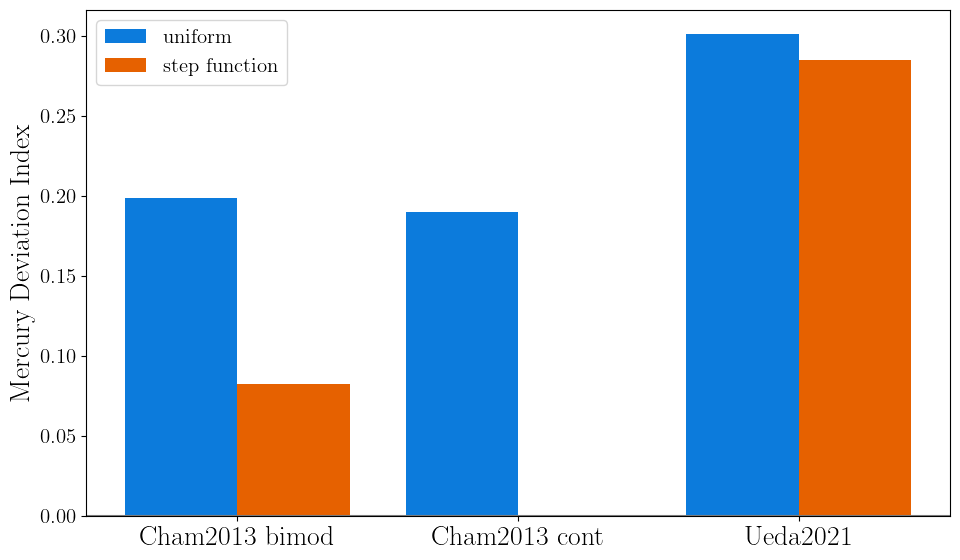

In [107]:
labels = list(uniforms.keys())  # assumes both dicts have same keys in same order
x = np.arange(len(labels))      # numeric positions
width = 0.4                     # width of each bar

plt.figure(figsize=(10,6))
plt.bar(x - width/2, uniforms.values(), width, label='uniform', color=colors[0])
plt.bar(x + width/2, steps.values(), width, label='step function', color=colors[1])
plt.axhline(0, color = 'gray')
plt.xticks(x, labels)
plt.ylabel("Mercury Deviation Index")
plt.legend(fontsize=15)
plt.tight_layout()

plt.savefig("merc_dev_index_minus_ave.pdf", dpi=30)
plt.show()


# Different plots in the cham_bi_tajer grid

In [108]:
bounds = cham_bi_tajer_steps['boundary'].unique()
percs = cham_bi_tajer_steps['percentage'].unique()

records = []

for bound in bounds:
    for perc in percs:
        df = cham_bi_tajer_steps_mercs[
            (cham_bi_tajer_steps_mercs['boundary'] == bound) &
            (cham_bi_tajer_steps_mercs['percentage'] == perc)
        ]
        dev_index = mercury_sim_index(df['mass'].values * sol_to_earth, df['cmf'].values)
        records.append({'bound': bound, 'perc': perc, 'dev_index': dev_index})

merc_devs_cham_step = pd.DataFrame(records)

/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:552: RuntimeWarning: Mean of empty slice.
  avg = a.mean(axis, **keepdims_kw)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/numpy/_core/_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


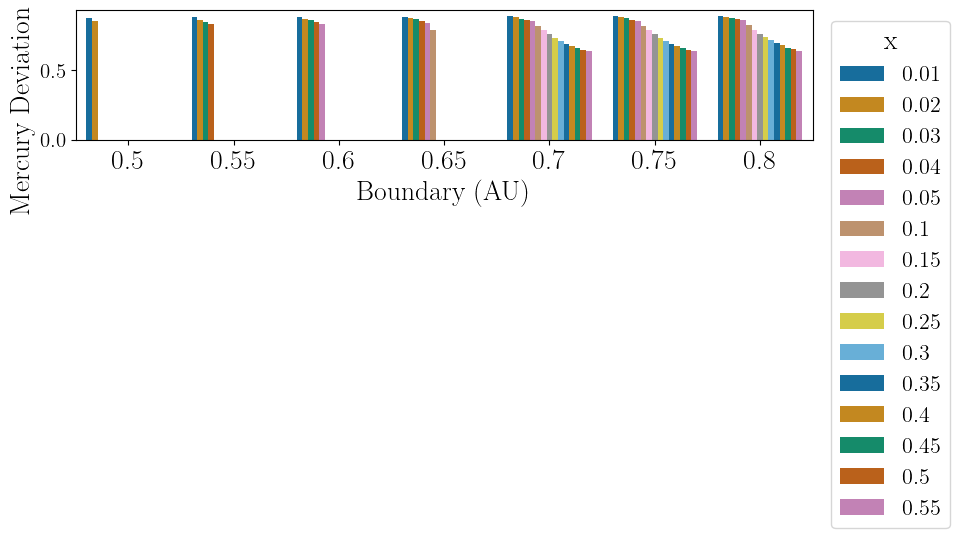

In [109]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,4))
sns.barplot(
    data=merc_devs_cham_step,
    x="bound", y="dev_index", hue="perc", palette="colorblind"
)
plt.legend(title="x", bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=16)
#plt.title("Mercury Deviation Index by Boundary and Percentage")
plt.tight_layout()
plt.ylabel("Mercury Deviation Index")
plt.xlabel("Boundary (AU)")
#plt.savefig('paper_plots/grid_plot_merc_devs.pdf', dpi=300)
plt.show()


In [110]:
#Other planets
semi_error = 0.02
semi_lower_bound = mercury['a'].values[0] - 0.02
semi_upper_bound = mercury['a'].values[0] + 0.02


cham_bi_tajer_venus = cham_bi_tajer_steps[(cham_bi_tajer_steps['semi'] > venus['a'].values[0] - semi_error ) &
                                   (cham_bi_tajer_steps['semi'] < venus['a'].values[0] + semi_error )]

cham_bi_tajer_earth = cham_bi_tajer_steps[(cham_bi_tajer_steps['semi'] > earth['a'].values[0] - semi_error ) &
                                   (cham_bi_tajer_steps['semi'] < earth['a'].values[0] + semi_error )]

cham_bi_tajer_mars = cham_bi_tajer_steps[(cham_bi_tajer_steps['semi'] > mars['a'].values[0] - semi_error ) &
                                   (cham_bi_tajer_steps['semi'] < mars['a'].values[0] + semi_error )]

# Compute average CMF for each planet's bin
avg_cmf_mercury = cham_bi_tajer_steps_mercs['cmf'].mean()
avg_a_mercury = cham_bi_tajer_steps_mercs['semi'].mean()
std_cmf_mercury = cham_bi_tajer_steps_mercs['cmf'].std()

avg_cmf_venus = cham_bi_tajer_venus['cmf'].mean()
avg_a_venus   = cham_bi_tajer_venus['semi'].mean()
std_cmf_venus = cham_bi_tajer_venus['cmf'].std()

avg_cmf_earth = cham_bi_tajer_earth['cmf'].mean()
avg_a_earth = cham_bi_tajer_earth['semi'].mean()
std_cmf_earth = cham_bi_tajer_earth['cmf'].std()

avg_cmf_mars  = cham_bi_tajer_mars['cmf'].mean()
avg_a_mars = cham_bi_tajer_mars['semi'].mean()
std_cmf_mars = cham_bi_tajer_mars['cmf'].std()

# cham_cont grid

In [111]:
bounds = cham_cont_steps['boundary'].unique()
percs = cham_cont_steps['percentage'].unique()

records = []

for bound in bounds:
    for perc in percs:
        df = cham_cont_steps_mercs[
            (cham_cont_steps_mercs['boundary'] == bound) &
            (cham_cont_steps_mercs['percentage'] == perc)
        ]
        dev_index = mercury_sim_index(df['mass'].values * sol_to_earth, df['cmf'].values)
        records.append({'bound': bound, 'perc': perc, 'dev_index': dev_index})

merc_devs_cham_cont_step = pd.DataFrame(records)

/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:552: RuntimeWarning: Mean of empty slice.
  avg = a.mean(axis, **keepdims_kw)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/numpy/_core/_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [112]:
merc_devs_cham_cont_step['perc'].unique()
percs = [0.1, 0.2, 0.3, 0.4]
bounds = [0.5, 0.6, 0.7, 0.8]
merc_dev_barplot = merc_devs_cham_cont_step[merc_devs_cham_cont_step['perc'].isin(percs) & merc_devs_cham_cont_step['bound'].isin(bounds)]

In [113]:
merc_dev_barplot = merc_dev_barplot.dropna()

In [114]:
min_cont = np.min(merc_dev_barplot['dev_index'])

In [115]:
merc_dev_barplot['dev-ave'] = merc_dev_barplot['dev_index'] - average_all
merc_dev_barplot['dev-min'] = merc_dev_barplot['dev_index'] - min_cont

In [116]:
average_all

np.float64(0.8751974646422073)

In [117]:
merc_dev_barplot

,bound,perc,dev_index,dev-ave,dev-min
1,0.5,0.1,0.692174,-0.183023,0.031166
19,0.6,0.1,0.674174,-0.201023,0.013166
37,0.7,0.1,0.697135,-0.178062,0.036127
39,0.7,0.2,0.673583,-0.201614,0.012575
55,0.8,0.1,0.782656,-0.092542,0.121648
57,0.8,0.2,0.712073,-0.163125,0.051065
59,0.8,0.3,0.674693,-0.200505,0.013685
61,0.8,0.4,0.661008,-0.214189,0.000000


In [125]:
print("Step function : Cham2013 bimodal = ", cham_bi_tajer_inds_step - min_cont)
print("Step function : Cham2013 cont = ", cham_cont_inds_step - min_cont)
print("Step function : Ueda = ", ueda_inds_step - min_cont)

Step function : Cham2013 bimodal =  0.12035348952318081
Step function : Cham2013 cont =  0.03790219211012147
Step function : Ueda =  0.3231644508736917


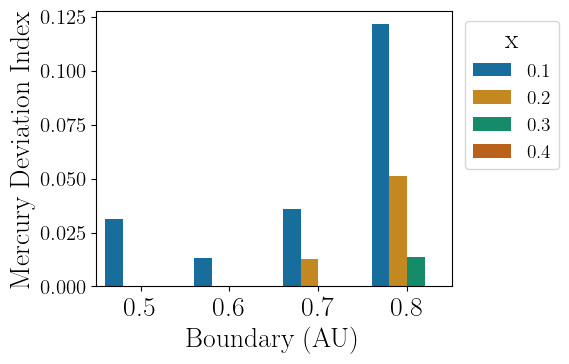

In [118]:
plt.figure(figsize=(6,4))
sns.barplot(
    data=merc_dev_barplot,
    x="bound", y="dev-min", hue="perc", palette="colorblind"
)
plt.legend(title="x", bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=14)
#plt.title("Mercury Deviation Index by Boundary and Percentage")
plt.tight_layout()
plt.ylabel("Mercury Deviation Index")
plt.xlabel("Boundary (AU)")
#plt.title('cham_cont')
plt.savefig('x_bound_merc_devs_cham_cont_minus.pdf', dpi=300)
plt.show()


In [119]:
merc_dev_barplot['dev_index'].std()

np.float64(0.038620468077462784)

In [120]:
bounds = ueda_steps['boundary'].unique()
percs = ueda_steps['percentage'].unique()

records = []

for bound in bounds:
    for perc in percs:
        df = ueda_steps_mercs[
            (ueda_steps_mercs['boundary'] == bound) &
            (ueda_steps_mercs['percentage'] == perc)
        ]
        dev_index = mercury_sim_index(df['mass'].values * sol_to_earth, df['cmf'].values)
        records.append({'bound': bound, 'perc': perc, 'dev_index': dev_index})

merc_devs_ueda_v5_step = pd.DataFrame(records)

/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:552: RuntimeWarning: Mean of empty slice.
  avg = a.mean(axis, **keepdims_kw)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/numpy/_core/_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


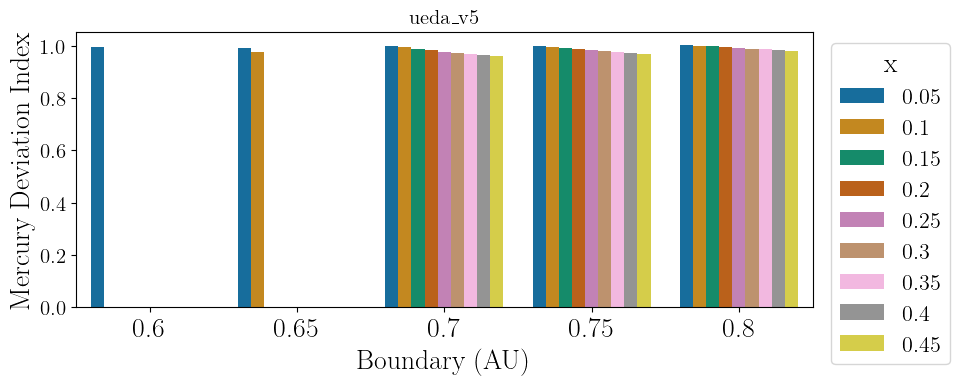

In [121]:
plt.figure(figsize=(10,4))
sns.barplot(
    data=merc_devs_ueda_v5_step,
    x="bound", y="dev_index", hue="perc", palette="colorblind"
)
plt.legend(title="x", bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=16)
#plt.title("Mercury Deviation Index by Boundary and Percentage")
plt.tight_layout()
plt.ylabel("Mercury Deviation Index")
plt.xlabel("Boundary (AU)")
plt.title('ueda_v5')
#plt.savefig('paper_plots/grid_plot_merc_devs.pdf', dpi=300)
plt.show()


In [122]:
np.std(merc_dev_barplot['dev-ave'])

np.float64(0.03612613991567645)

In [123]:
merc_dev_barplot

,bound,perc,dev_index,dev-ave,dev-min
1,0.5,0.1,0.692174,-0.183023,0.031166
19,0.6,0.1,0.674174,-0.201023,0.013166
37,0.7,0.1,0.697135,-0.178062,0.036127
39,0.7,0.2,0.673583,-0.201614,0.012575
55,0.8,0.1,0.782656,-0.092542,0.121648
57,0.8,0.2,0.712073,-0.163125,0.051065
59,0.8,0.3,0.674693,-0.200505,0.013685
61,0.8,0.4,0.661008,-0.214189,0.000000


In [124]:
np.std(merc_dev_barplot['dev_index'])

np.float64(0.03612613991567645)